In [4]:
import cv2
import numpy as np
import random
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()
name = list(uploaded.keys())[0]

img = cv2.imdecode(
    np.frombuffer(uploaded[name], np.uint8),
    cv2.IMREAD_GRAYSCALE
)

Saving 2ecf067a2069128f44d75d25a32e219e.jpg to 2ecf067a2069128f44d75d25a32e219e.jpg


In [5]:
# Histogram
hist, _ = np.histogram(img, 256, (0, 256))
p = hist / hist.sum()

# Fitness function
def fitness(t):
    w1 = p[:t].sum()
    w2 = p[t:].sum()

    if w1 == 0 or w2 == 0:
        return 0

    m1 = np.sum(np.arange(t) * p[:t]) / w1
    m2 = np.sum(np.arange(t, 256) * p[t:]) / w2
    mt = np.sum(np.arange(256) * p)

    return w1 * (m1-mt)**2 + w2 * (m2-mt)**2


# Initial population
population = [random.randint(1, 254) for _ in range(20)]
history = []

for generation in range(30):

    scores = [fitness(x) for x in population]

    # Select best 5
    parents = [
        x for _, x in
        sorted(zip(scores, population), reverse=True)[:5]
    ]

    best = parents[0]
    history.append(fitness(best))

    # Crossover + mutation
    new_population = parents.copy()

    while len(new_population) < 20:

        a, b = random.sample(parents, 2)

        child = (a + b) // 2       # crossover

        if random.random() < 0.1:  # mutation
            child = random.randint(1, 254)

        new_population.append(child)

    population = new_population


# Final result
threshold = max(population, key=fitness)

segmented = (img > threshold) * 255

print("Optimal Threshold:", threshold)
print("Fitness:", round(fitness(threshold), 2))
print("Generations:", 30)

Optimal Threshold: 118
Fitness: 2111.09
Generations: 30


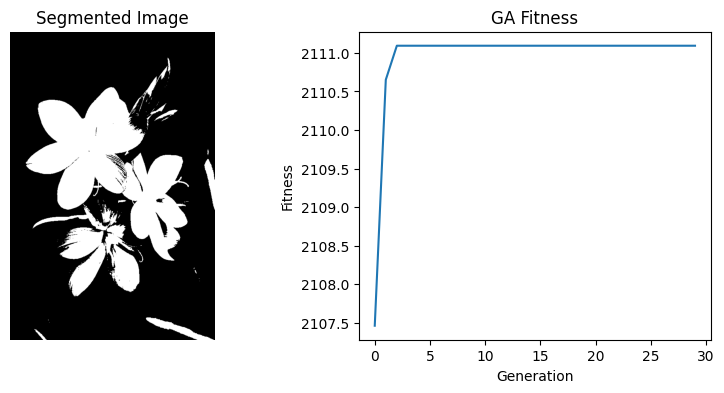

In [6]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.imshow(segmented, cmap="gray")
plt.title("Segmented Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.plot(history)
plt.title("GA Fitness")
plt.xlabel("Generation")
plt.ylabel("Fitness")

plt.show()